In [1]:
from radio_utilities import *

# Read data

In [3]:
with fits.open('./20260622_SUN_VINCENT.fits') as hdul:
    astro_table = Table(hdul[1].data)
    data_vin = astro_table.to_pandas()
    
x_data_vin = data_vin['JD']
y_data_vin = data_vin['RIGHT_POL'].values

# Estimate the Beam Angle of the main lobe

In [7]:
beam = get_beam_angle(x_data_vin,y_data_vin)
print('Main beam angle: %.2f deg'%beam)

Main beam angle: 4.60 deg


# Gaussian Fit

### Gaussian Fit ###
Amplitude 120.77312643689326
Centre [Julian date] 2461213.74750501
Sigma [Days] 0.005721988127342589
Sigma [min] 8.239662903373327
Background floor [adu] 41.933884029219655
FWHM [days] 0.013474252082028876
FWHM [min] 19.402922998121582
Estimated antenna beam with 0.25 deg/min 4.8507307495303955


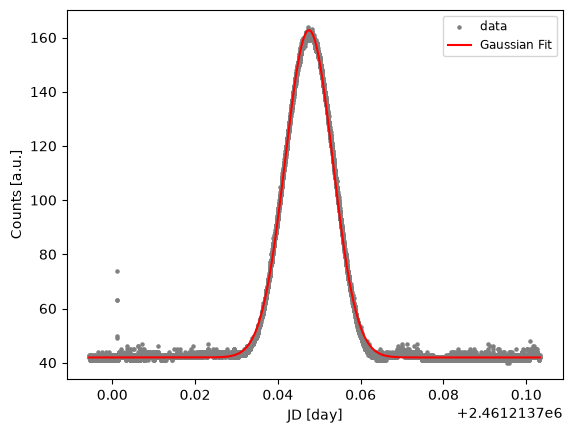

In [9]:
Amp_adu, centre_jd, sigma_jd, floor_adu, fwhm_day =  gauss_fit(x_data_vin,y_data_vin,verbose=True,plot=True)

In [14]:
def get_conversion_K(julian_dates, counts_adu, amp_adu, solar_flux_sfu, aperture_eff=0.60):
    k_B = 1.38e-23  # Boltzmann constant [J/K]
    dish_diameter = 3.0  # Dish diameter in meters
    

    # Calculate Effective Aperture
    A_geom = np.pi * (dish_diameter / 2) ** 2
    A_e = aperture_eff * A_geom

    # Convert SFU to W/m^2/Hz
    S_flux = solar_flux_sfu * 1e-22

    # Expected Antenna Temperature of the Sun
    T_sun_expected = (S_flux * A_e) / (2 * k_B)

    # Calculate Calibration Factor K
    K = T_sun_expected / amp_adu
    
    return K

In [38]:
# NOAA's live JSON feed for daily F10.7 flux measurements
url = "https://services.swpc.noaa.gov/json/f107_cm_flux.json"
# Load directly into a Pandas DataFrame
df_daily = pd.read_json(url)
# Convert timestamp column to datetime
df_daily['time_tag'] = pd.to_datetime(df_daily['time_tag'])
# estimate Flux F10.7 (2.8GHz) on a specific date 
f107 = (df_daily[df_daily['time_tag']=='2026-07-22 17:00:00']['flux']).values[0]
print('Flux on 2026-07-22 22:00:00 at 10.7 cm: ',f107)
#Alternatively f107 can be found at 

f14 = f107*(1.4/2.8)**0.8 # (1.4/2.8)**0.8=0.574
print('Flux on 2026-07-22 22:00:00 at 1.4 GHz: ',f14)
K = get_conversion_K(x_data_vin,y_data_vin,amp_adu=Amp_adu,solar_flux_sfu=f14)

print('Conversion factor between ADU to Antenna temperature: ',K)

Flux on 2026-07-22 22:00:00 at 10.7 cm:  150.0
Flux on 2026-07-22 22:00:00 at 1.4 GHz:  86.15237662477762
Conversion factor between ADU to Antenna temperature:  10.961538477811047


# Plot Antenna Temperature

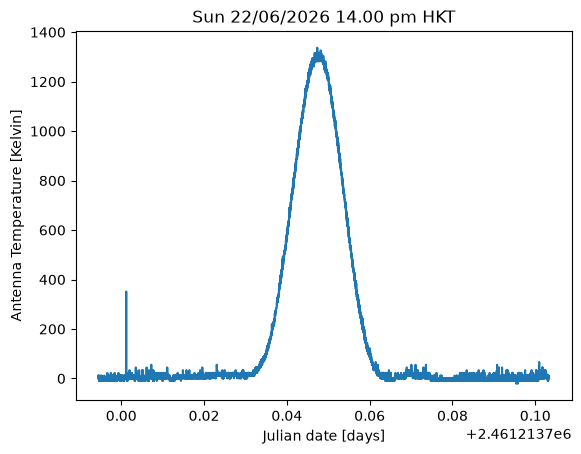

In [28]:
AntennaTemp = (y_data_vin-floor_adu)*K

plt.plot(x_data_vin, AntennaTemp)
plt.xlabel('Julian date [days]')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title('Sun 22/06/2026 14.00 pm HKT')

plt.show()

# Convert to Temperature Brightness 

In [30]:
def ta_to_tb(T_A, beamwidth_deg=4.6, source_deg=0.553, eta_mb=0.7):
    """
    Converts Antenna Temperature to Brightness Temperature using a measured beamwidth.
    """
    # Convert measured beamwidth to radians
    theta_beam_rad = np.radians(beamwidth_deg)
    
    # Gaussian beam solid angle of the telescope
    omega_A = 1.133 * (theta_beam_rad ** 2)
    
    # Source solid angle (~0.533 degrees diameter for the Sun)
    theta_source_rad = np.radians(0.533)
    omega_source = np.pi * (theta_source_rad / 2) ** 2
    
    # Dilution ratio
    dilution_ratio = omega_A / omega_source
    
    # Intrinsic Brightness Temperature
    T_B = (T_A / eta_mb) * dilution_ratio
    
    return T_B

In [32]:
BrightnessTemp = ta_to_tb(AntennaTemp,beamwidth_deg=beam)

# Plot Temperature Brightness

Temperature Brightness (peak) =  205406.95107276825


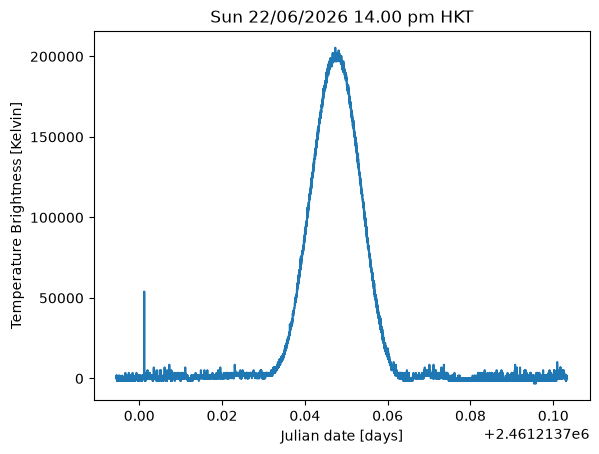

In [39]:
plt.plot(x_data_vin, BrightnessTemp)
plt.xlabel('Julian date [days]')
plt.ylabel('Temperature Brightness [Kelvin]')
plt.title('Sun 22/06/2026 14.00 pm HKT')
print('Temperature Brightness (peak) = ',BrightnessTemp.max() )
plt.show()